# Visualizing Distributions, Categories, and Trends

Choosing between a **histogram**, a **bar chart** and a **line chart** depends on whether you are analysing the **distribution of values**, **comparing distinct groups**, or **tracking progression over an ordered sequence**.

---

## 1. Comparison Matrix

| Feature | Histogram | Bar Chart | Line Chart |
| --- | --- | --- | --- |
| **Purpose** | Show the frequency **distribution** of a numeric variable | **Compare an aggregate metric** across categories | Track **trends** over an ordered axis |
| **X-axis** | **Continuous numeric**, divided into ranges (bins) | **Categorical / discrete** groups (nominal or ordinal) | **Ordered / sequential** variable (time, steps) |
| **Y-axis** | **Frequency**, count or density | **Summary metric** (total, average, count) | **Metric value** (price, latency, temperature) |
| **Spacing** | **No gaps** between bars (numeric continuity) | **Gaps** between bars (separate categories) | Points joined by **line segments** |
| **Reordering** | **Not allowed** — bins follow numeric order | **Allowed / recommended** (e.g. sort by value) | **Not allowed** — must follow time/sequence order |
| **Main insight** | Skewness, spread, centre, outliers, modality | Ranking and differences between groups | Rate of change, seasonality, volatility |

---

## 2. Visual Signatures

### A. Histogram (continuous distribution)
Bars touch to represent continuous intervals.

```text
Frequency
  ▲
 8│      ┌───┐
 6│  ┌───┤   ├───┐
 4│  │   │   │   ├───┐
 2│──┴───┴───┴───┴───┴──►
    0-10 10-20 20-30 30-40 (numeric bins)
```

### B. Bar chart (discrete categories)
Gaps between bars emphasise separate entities.

```text
Total metric value
  ▲
10│  ┌───┐
 8│  │   │       ┌───┐
 6│  │   │       │   │
 4│  │   │ ┌───┐ │   │
 0└──┴───┴─┴───┴─┴───┴──►
     Apples Bananas Oranges (categories)
```

### C. Line chart (sequential progression)
Points are connected in order to convey direction and rate of change.

```text
Metric value
  ▲
  │          *
  │        /   \
  │   *---*     *
  │  /           \
  │ *             *
  └───────────────────►
    Jan   Feb   Mar   Apr (time)
```

---

## 3. Chart Profiles

### Histogram
- **What it does:** groups continuous observations into ranges (bins) and counts how many fall into each.
- **Typical questions:**
  - *Is API latency roughly normal, or does it have a long right tail?*
  - *Around which price range do most transactions cluster?*
- **Examples:** customer ages, server response times, exam scores.

### Bar chart
- **What it does:** compares one aggregate metric across non-overlapping categories.
- **Typical questions:**
  - *Which department generated the most revenue this quarter?*
  - *How does conversion rate compare across browsers?*
- **Examples:** revenue per region, bug count per module, stock per warehouse.

### Line chart
- **What it does:** connects points in order to show the direction and size of change over time.
- **Typical questions:**
  - *At what time of day does CPU load spike?*
  - *Is monthly user retention trending up or down?*
- **Examples:** daily active users over 90 days, sensor temperature over 24 hours, stock prices.

---

## 4. Decision Guide

```text
What question do you need to answer?
 │
 ├── Distribution: "How are individual values spread?"
 │    └──► HISTOGRAM   (X = numeric bins, Y = count)
 │
 ├── Comparison: "How do totals or averages differ between groups?"
 │    └──► BAR CHART   (X = categories, Y = aggregate metric)
 │
 └── Progression: "How does a metric change over time or sequence?"
      └──► LINE CHART  (X = time/order, Y = metric value)
```

---

## 5. Python Example (`seaborn` + `matplotlib`)

Each chart gets data that suits it: 500 latency measurements for the histogram, one revenue total per platform for the bar chart, and 30 days of a daily metric for the line chart.

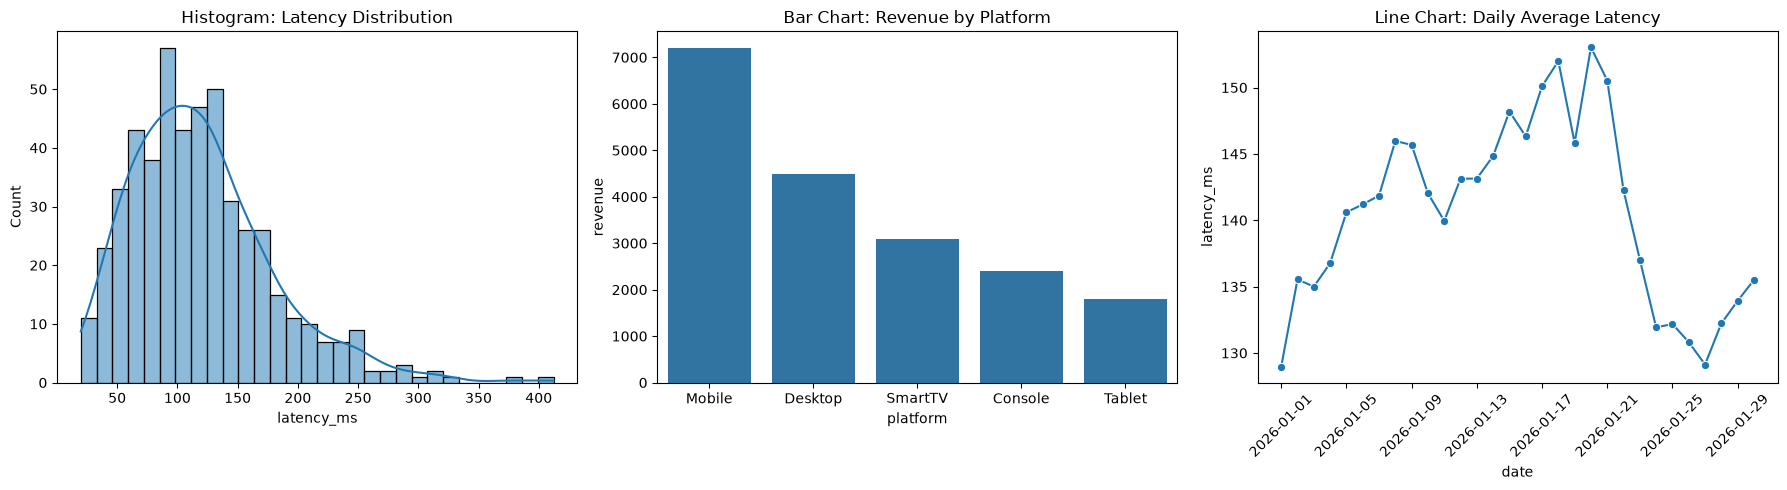

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

rng = np.random.default_rng(42)

# Histogram data: 500 right-skewed latency measurements
latency = pd.DataFrame({'latency_ms': rng.gamma(shape=4, scale=30, size=500)})

# Bar chart data: one total per category, sorted by value
revenue = pd.DataFrame({
    'platform': ['Desktop', 'Mobile', 'Tablet', 'SmartTV', 'Console'],
    'revenue': [4500, 7200, 1800, 3100, 2400],
}).sort_values('revenue', ascending=False)

# Line chart data: a daily metric over 30 days
daily = pd.DataFrame({
    'date': pd.date_range('2026-01-01', periods=30, freq='D'),
    'latency_ms': 120 + rng.normal(0, 5, 30).cumsum(),
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram: distribution of numeric values
sns.histplot(data=latency, x='latency_ms', bins=30, kde=True, ax=axes[0])
axes[0].set_title('Histogram: Latency Distribution')

# 2. Bar chart: aggregate comparison across categories
sns.barplot(data=revenue, x='platform', y='revenue', ax=axes[1])
axes[1].set_title('Bar Chart: Revenue by Platform')

# 3. Line chart: metric trend over time
sns.lineplot(data=daily, x='date', y='latency_ms', marker='o', ax=axes[2])
axes[2].set_title('Line Chart: Daily Average Latency')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()